In [1]:
from process_results.utils_io import load_log_files
from pathlib import Path
from utils.utils import plot_config
import matplotlib.pyplot as plt
import numpy as np
import pickle as pk
import torch
import random
from utils.channel_model import expModel
from graph_dataset_generator.config_generator import sort_feasible_config

In [2]:
date_folder = "multi_exp_timevsnagents"
base_folder=Path(f"data_sync/resultados/{date_folder}/")
experimentType =  "dynamic"#"static" #"static" "trebol" 
output=Path('./data_sync/paper_results/')


In [3]:
files = []
for file in base_folder.rglob("*.pkl"):
    fname = file.name.lower()
    if experimentType in fname:
        files.append(file)

 
log_data = load_log_files(files)
print(f"Loaded {len(log_data)} experiments from {len(files)} files.")


Loaded 80 data files.
Example keys: dict_keys(['free_hist', 'exp', 'ini', 'noSA', 'modelos', 'maxL2'])
Loaded 80 experiments from 80 files.


In [4]:
print(log_data[10]['modelos'].keys())

dict_keys(['real_5', 'real_15'])


In [5]:
excluded_variants=["real_15_modelY", "real_15_modelG","real_25_modelY", "real_25_modelG", "curl_modelY", "curl_modelG"]

In [6]:
if 'modelos' in log_data[0].keys():      
    resultados_lista = [
        {
            **{'ini': d['ini'], 'maxL2': d.get('maxL2', None), 'noSA': d.get('noSA', None), 'exp': d['exp']},
            **{f"{modelo}_{subkey}": valor
            for modelo, subdict in d['modelos'].items()
            for subkey, valor in subdict.items()}
        }
        for d in log_data
    ]
variants = [k for k in resultados_lista[0] if k not in {'ini','exp'}.union(excluded_variants or [])]
time_per_total_agents = {}
for var in variants:
    time_per_total_agents[var]={}

mean_times = {var: np.mean([data[var]['time_hist'] for data in resultados_lista]) for var in variants}    
for data in resultados_lista:
    total_agents=data['exp']['task_agents']+data['exp']['comm_agents']
    for var in variants:
        if total_agents not in time_per_total_agents[var]:
            time_per_total_agents[var][total_agents]=[]
            
        time_per_total_agents[var][total_agents].append([data[var]['time_hist']])
import pickle        
with open(output/'resultados_tiempos.pkl', 'wb') as f:
    pickle.dump(time_per_total_agents, f)

In [9]:
print(time_per_total_agents['noSA'].keys())

for key in time_per_total_agents.keys():
    print(f"Variant: {key}")
    for agents in sorted(time_per_total_agents[key].keys()):
        times = time_per_total_agents[key][agents]
        mean_time = np.mean([t[0] for t in times])
        print(f"  Total Agents: {agents}, Mean Time: {mean_time:.4f} seconds")
        print(times)

dict_keys([5, 12, 19, 25, 30, 35, 40, 50])
Variant: maxL2
  Total Agents: 5, Mean Time: 0.0460 seconds
[[[0.04776334762573242, 0.04564642906188965, 0.04417252540588379, 0.044779300689697266, 0.0489954948425293, 0.0453641414642334, 0.04613447189331055, 0.04568958282470703, 0.04558563232421875, 0.04580116271972656]], [[0.0462040901184082, 0.04438591003417969, 0.0463254451751709, 0.04669761657714844, 0.04416298866271973, 0.04412651062011719, 0.04355931282043457, 0.044503211975097656, 0.04526567459106445, 0.046022653579711914]], [[0.04445934295654297, 0.047837257385253906, 0.04400515556335449, 0.04576754570007324, 0.04478883743286133, 0.0435481071472168, 0.04418587684631348, 0.04537391662597656, 0.04493069648742676, 0.04441070556640625]], [[0.04438638687133789, 0.044345855712890625, 0.04601287841796875, 0.04556679725646973, 0.047686100006103516, 0.044576406478881836, 0.04435014724731445, 0.044844865798950195, 0.04650378227233887, 0.04493212699890137]], [[0.04447817802429199, 0.045654535293

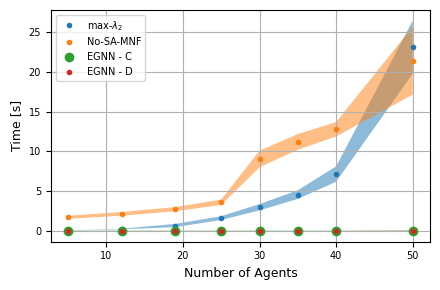

In [13]:
plt.figure(figsize=(4.5,3))  # <-- tamaño de la imagen

labels=[v for v in variants]
labelsplt = [label.replace('real_5_modelY','EGNN - C').replace('real_5_modelG','EGNN - D').replace('noSA','No-SA-MNF').replace('maxL2',f"max-$\lambda_2$") for label in labels]
dict_labels = {v: labelsplt[i] for i,v in enumerate(variants)}

for var, num_agents_list in time_per_total_agents.items():
    num_agents=num_agents_list.keys()
    values=[time_per_total_agents[var][num] for num in num_agents]
    means=[np.mean(v) for v in values]
    stds=[np.std(v) for v in values]
    if var == 'real_5_modelY':
        plt.plot(list(num_agents_list.keys()), means, 'o', label=dict_labels[var])
    else:
        plt.plot(list(num_agents_list.keys()), means, '.', label=dict_labels[var])
    plt.fill_between(list(num_agents_list.keys()),
                     np.array(means)-np.array(stds),
                     np.array(means)+np.array(stds), alpha=0.5)
    
plt.tick_params(axis='both', labelsize=7)

plt.xlabel("Number of Agents",fontsize=9)
plt.ylabel("Time [s]",fontsize=9)
plt.grid()
#plt.title(f"Mean Time vs Total Agents ({experimentType.capitalize()} Experiment)")
plt.legend(fontsize=7)
plt.tight_layout()
plt.savefig(output/"time_per_total_agents.pdf", dpi=300)
plt.savefig(output/"time_per_total_agents.png", dpi=300)


In [9]:
for data in log_data:
    print(f'cantidad de agentes: {data["exp"]["task_agents"]+data["exp"]["comm_agents"]} - tiempo L2: {data["modelos"]["real_5"]["modelY"]["time_hist"]}')


cantidad de agentes: 5 - tiempo L2: [0.3130490779876709, 0.008641958236694336, 0.008418083190917969, 0.00895237922668457, 0.011237621307373047, 0.009192943572998047, 0.011096954345703125, 0.010650634765625, 0.010906219482421875, 0.012475252151489258]
cantidad de agentes: 5 - tiempo L2: [0.010787248611450195, 0.013091087341308594, 0.012635946273803711, 0.026017189025878906, 0.011353015899658203, 0.010959148406982422, 0.010765314102172852, 0.014620542526245117, 0.01429128646850586, 0.01075601577758789]
cantidad de agentes: 5 - tiempo L2: [0.013717174530029297, 0.011198282241821289, 0.01122736930847168, 0.02914142608642578, 0.014494895935058594, 0.011077642440795898, 0.011414289474487305, 0.010731935501098633, 0.010800838470458984, 0.01627826690673828]
cantidad de agentes: 5 - tiempo L2: [0.014201641082763672, 0.010816812515258789, 0.015198945999145508, 0.011029958724975586, 0.012528181076049805, 0.009494781494140625, 0.010544538497924805, 0.010488033294677734, 0.009428977966308594, 0.009